# Proyek Data Science: Peramalan Kategori ISPU DKI Jakarta
## Prediksi Kategori Kualitas Udara H+1 Berbasis Data Deret Waktu (2010–2025)

**Studi kasus:** Sistem peringatan dini kualitas udara Jakarta  
**Metode:** Klasifikasi (*supervised learning*) dengan pembagian data kronologis  
**Target:** Kategori ISPU pada hari berikutnya (`target_h1`) untuk setiap stasiun pemantau.

> Notebook ini dibuat dengan mengikuti alur notebook contoh *Flight Price*, tetapi isi, variabel, analisis, dan model disesuaikan dengan laporan ISPU. Letakkan `ispu_dki1.csv` sampai `ispu_dki5.csv` (opsional `ispu_dki_all.csv`) dalam folder `data/raw/` sebelum menjalankan seluruh notebook.

## 1. Business Understanding

### 1.1 Latar Belakang dan Masalah
Informasi ISPU yang tersedia umumnya menggambarkan kondisi saat ini atau kejadian yang sudah berlangsung. Proyek ini menguji apakah kategori ISPU satu hari ke depan dapat diperkirakan dari riwayat pengukuran harian tiap Stasiun Pemantau Kualitas Udara (SPKU).

### 1.2 Tujuan
- Memprediksi kategori ISPU hari berikutnya (H+1) per stasiun.
- Membandingkan model machine learning dengan baseline sederhana, yaitu kategori besok sama dengan kategori hari ini (*persistence*).
- Mengutamakan **Macro-F1** dan **recall kategori “Tidak Sehat” atau lebih buruk**, karena kelas buruk penting untuk sistem peringatan dini.
- Menghindari kebocoran data dengan membagi data secara kronologis dan hanya memakai fitur dari hari sebelumnya.

### 1.3 Batasan
Data berasal dari lima stasiun DKI Jakarta. File per stasiun memiliki celah tahun 2022 dan data tahun 2025 yang terbatas. Dataset tidak mencakup cuaca, lalu lintas, maupun aktivitas industri. Hasil model adalah alat bantu analisis, bukan pengganti informasi resmi.

## 2. Data Gathering & Ingestion

### 2.1 Import Library

In [17]:
import glob
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

RANDOM_STATE = 42
DATA_DIR = Path("data/raw")

### 2.2 Memuat Dataset Lima Stasiun
Kode mencari file `ispu_dki1.csv` sampai `ispu_dki5.csv`. Nama kolom dinormalisasi agar huruf besar/kecil dan spasi tidak mengganggu pemrosesan. Jika file belum diletakkan pada folder yang sesuai, kode akan memberi pesan yang jelas.

In [18]:
def load_csv(path):
    data = pd.read_csv(path)
    data.columns = data.columns.str.strip().str.lower()
    data = data.rename(columns={"category": "categori", "date": "tanggal"})
    if "tanggal" not in data.columns:
        raise ValueError(f"Kolom tanggal tidak ditemukan pada {path.name}. Kolom tersedia: {list(data.columns)}")
    data["tanggal"] = pd.to_datetime(data["tanggal"], errors="coerce", dayfirst=False)
    if "stasiun" not in data.columns:
        data["stasiun"] = path.stem.replace("ispu_", "").upper()
    return data
from pathlib import Path

DATA_DIR = Path(".")
station_files = sorted(DATA_DIR.glob("ispu_dki[1-5].csv"))
if not station_files:
    raise FileNotFoundError(
        "File data belum ditemukan. Buat folder data/raw/ lalu masukkan "
        "ispu_dki1.csv, ispu_dki2.csv, ispu_dki3.csv, ispu_dki4.csv, dan ispu_dki5.csv."
    )

frames = [load_csv(path) for path in station_files]
df_raw = pd.concat(frames, ignore_index=True)
print("File yang dimuat:", [p.name for p in station_files])
print("Ukuran data gabungan:", df_raw.shape)
display(df_raw.head())

File yang dimuat: ['ispu_dki1.csv', 'ispu_dki2.csv', 'ispu_dki3.csv', 'ispu_dki4.csv', 'ispu_dki5.csv']
Ukuran data gabungan: (25865, 11)


,tanggal,stasiun,pm25,pm10,so2,co,o3,no2,max,critical,categori
0,2010-01-01,DKI1 (Bunderan HI),NaN,60.0,4.0,73.0,27.0,14.0,73.0,CO,SEDANG
1,2010-01-02,DKI1 (Bunderan HI),NaN,32.0,2.0,16.0,33.0,9.0,33.0,O3,BAIK
2,2010-01-03,DKI1 (Bunderan HI),NaN,27.0,2.0,19.0,20.0,9.0,27.0,PM10,BAIK
3,2010-01-04,DKI1 (Bunderan HI),NaN,22.0,2.0,16.0,15.0,6.0,22.0,PM10,BAIK
4,2010-01-05,DKI1 (Bunderan HI),NaN,25.0,2.0,17.0,15.0,8.0,25.0,PM10,BAIK


### 2.3 Sumber Data dan Kamus Data
Sumber yang dicantumkan dalam laporan adalah dataset **Air Quality Index in Jakarta** oleh Taufiq Pohan (`senadu34`) di Kaggle, yang menghimpun data ISPU dari lima SPKU DKI Jakarta.

| Kolom | Keterangan |
|---|---|
| `tanggal` | Tanggal pengukuran harian |
| `stasiun` | Kode stasiun DKI1–DKI5 |
| `pm10`, `pm25` | Sub-indeks partikulat PM10 dan PM2.5 |
| `so2`, `co`, `o3`, `no2` | Sub-indeks polutan terkait |
| `max` | Nilai ISPU maksimum pada hari tersebut |
| `critical` | Polutan kritis pada hari tersebut |
| `categori` | Kategori ISPU yang menjadi dasar target |

Nama kolom aktual bisa berbeda antar berkas. Periksa hasil `df_raw.columns` dan sesuaikan jika dataset yang diunduh memiliki struktur berbeda.

## 3. Data Understanding dan Exploratory Data Analysis (EDA)

### 3.1 Struktur Data, Tipe Data, dan Rentang Tanggal

In [19]:
print("=== Informasi dataset ===")
df_raw.info()
print("\nRentang tanggal:", df_raw["tanggal"].min(), "sampai", df_raw["tanggal"].max())
print("\nJumlah baris per tahun:")
display(df_raw.groupby(df_raw["tanggal"].dt.year).size().rename("jumlah_baris").to_frame())
print("\nJumlah data per stasiun:")
display(df_raw["stasiun"].value_counts().sort_index().to_frame("jumlah_baris"))

=== Informasi dataset ===
<class 'pandas.DataFrame'>
RangeIndex: 25865 entries, 0 to 25864
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   tanggal   25865 non-null  datetime64[us]
 1   stasiun   25865 non-null  str           
 2   pm25      5354 non-null   float64       
 3   pm10      22378 non-null  float64       
 4   so2       22855 non-null  float64       
 5   co        23027 non-null  float64       
 6   o3        22793 non-null  float64       
 7   no2       22851 non-null  float64       
 8   max       25806 non-null  float64       
 9   critical  23456 non-null  str           
 10  categori  25865 non-null  str           
dtypes: datetime64[us](1), float64(7), str(3)
memory usage: 2.9 MB

Rentang tanggal: 2010-01-01 00:00:00 sampai 2025-02-28 00:00:00

Jumlah baris per tahun:


,jumlah_baris
tanggal,
2010,1825
2011,1825
2012,1830
2013,1825
2014,1825
2015,1825
2016,1830
2017,1825
2018,1825



Jumlah data per stasiun:


,jumlah_baris
stasiun,
DKI1 (Bunderan HI),5173
DKI2 (Kelapa Gading),5173
DKI3 (Jagakarsa),5173
DKI4 (Lubang Buaya),5173
DKI5 (Kebon Jeruk),5173


### 3.2 Pemeriksaan Missing Value dan Duplikasi
Nilai kosong perlu dibedakan dari parameter yang memang belum tersedia pada periode awal. Nilai polutan dikonversi ke numerik; nilai teks yang tidak dapat dikonversi akan menjadi `NaN` dan dihitung.

In [20]:
df = df_raw.copy()
numeric_candidates = ["pm10", "pm25", "so2", "co", "o3", "no2", "max"]
numeric_cols = [c for c in numeric_candidates if c in df.columns]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing value per kolom:")
display(df.isna().sum().to_frame("jumlah_missing"))
print("\nPersentase missing (%):")
display((df.isna().mean() * 100).round(2).to_frame("missing_persen"))
print("\nDuplikat kombinasi tanggal dan stasiun:", df.duplicated(["tanggal", "stasiun"]).sum())
print("\nKategori yang ditemukan:")
if "categori" in df.columns:
    display(df["categori"].value_counts(dropna=False).to_frame("jumlah"))
else:
    raise KeyError("Kolom categori/category tidak ditemukan. Periksa nama kolom dataset.")

Missing value per kolom:


,jumlah_missing
tanggal,0
stasiun,0
pm25,20511
pm10,3487
so2,3010
co,2838
o3,3072
no2,3014
max,59
critical,2409



Persentase missing (%):


,missing_persen
tanggal,0.00
stasiun,0.00
pm25,79.30
pm10,13.48
so2,11.64
co,10.97
o3,11.88
no2,11.65
max,0.23
critical,9.31



Duplikat kombinasi tanggal dan stasiun: 0

Kategori yang ditemukan:


,jumlah
categori,
SEDANG,16043
BAIK,4213
TIDAK SEHAT,2992
TIDAK ADA DATA,2409
SANGAT TIDAK SEHAT,207
BERBAHAYA,1


### 3.3 Distribusi Kategori ISPU
Grafik ini membantu melihat ketidakseimbangan kelas. Angka dan insight akan dihasilkan dari dataset yang benar-benar dimuat, bukan diisi secara manual.

In [21]:
print("Kolom df:", df.columns.tolist())
print("Kolom df_raw:", df_raw.columns.tolist())

Kolom df: ['tanggal', 'stasiun', 'pm25', 'pm10', 'so2', 'co', 'o3', 'no2', 'max', 'critical', 'categori']
Kolom df_raw: ['tanggal', 'stasiun', 'pm25', 'pm10', 'so2', 'co', 'o3', 'no2', 'max', 'critical', 'categori']


### 3.4 Distribusi Kategori per Stasiun

categori,BAIK,BERBAHAYA,SANGAT TIDAK SEHAT,SEDANG,TIDAK ADA DATA,TIDAK SEHAT
stasiun,,,,,,
DKI1 (Bunderan HI),22.98,0.00,0.00,71.22,2.20,3.60
DKI2 (Kelapa Gading),14.54,0.02,2.98,62.01,6.86,13.59
DKI3 (Jagakarsa),16.12,0.00,0.19,62.65,7.89,13.15
DKI4 (Lubang Buaya),12.02,0.00,0.14,65.20,8.10,14.54
DKI5 (Kebon Jeruk),15.77,0.00,0.70,49.04,21.52,12.97


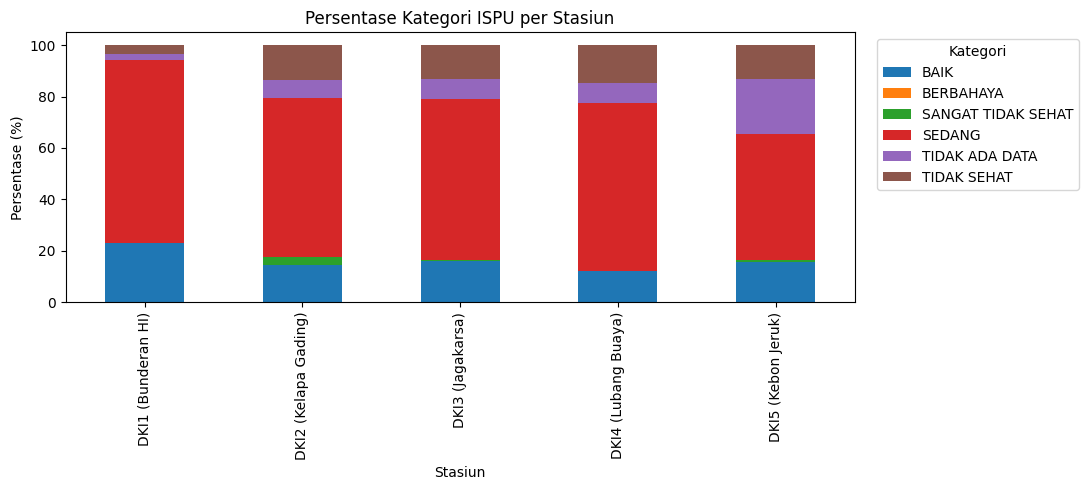

In [22]:
station_category = pd.crosstab(df["stasiun"], df["categori"], normalize="index") * 100
display(station_category.round(2))
station_category.plot(kind="bar", stacked=True, figsize=(11, 5))
plt.title("Persentase Kategori ISPU per Stasiun")
plt.xlabel("Stasiun")
plt.ylabel("Persentase (%)")
plt.legend(title="Kategori", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 3.5 Pola Musiman dan Tren Tahunan

,rata_rata_ispu
bulan,
1,48.74
2,55.13
3,63.34
4,65.72
5,71.14
6,71.78
7,74.10
8,75.33
9,76.46


,rata_rata_ispu
tahun,
2010,17.01
2011,58.46
2012,78.91
2013,76.90
2014,66.94
2015,63.54
2016,65.44
2017,66.60
2018,80.11


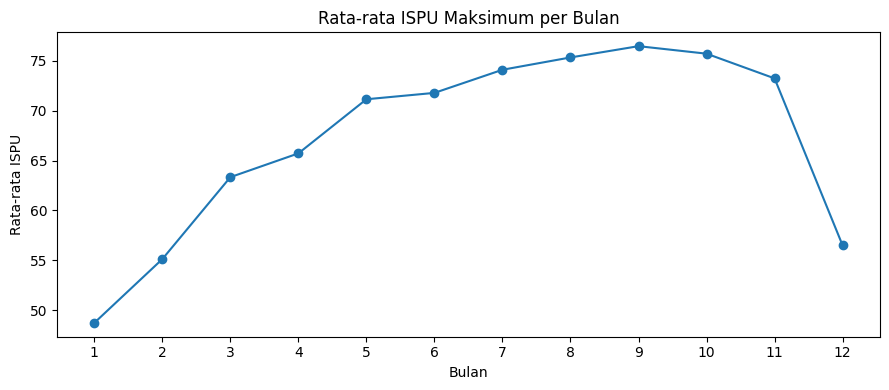

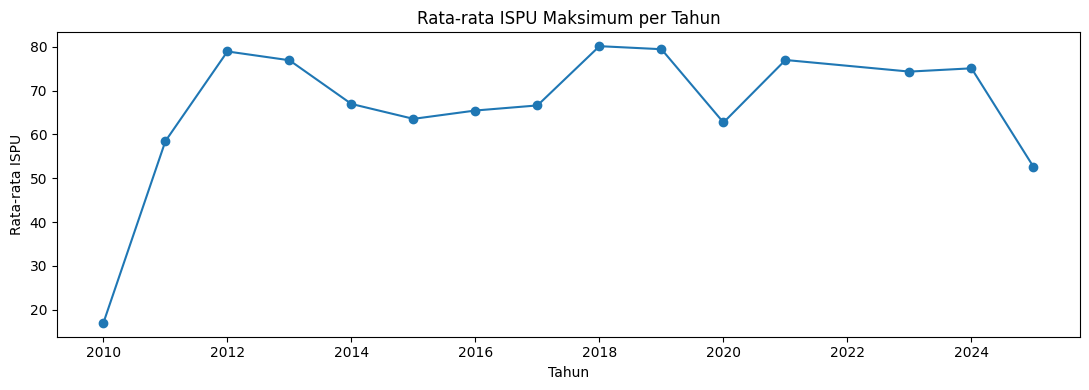

In [23]:
df["tahun"] = df["tanggal"].dt.year
df["bulan"] = df["tanggal"].dt.month

if "max" in df.columns:
    monthly_mean = df.groupby("bulan")["max"].mean()
    yearly_mean = df.groupby("tahun")["max"].mean()
    display(monthly_mean.rename("rata_rata_ispu").to_frame().round(2))
    display(yearly_mean.rename("rata_rata_ispu").to_frame().round(2))

    monthly_mean.plot(marker="o", figsize=(9, 4))
    plt.title("Rata-rata ISPU Maksimum per Bulan")
    plt.xlabel("Bulan")
    plt.ylabel("Rata-rata ISPU")
    plt.xticks(range(1, 13))
    plt.tight_layout()
    plt.show()

    yearly_mean.plot(marker="o", figsize=(11, 4))
    plt.title("Rata-rata ISPU Maksimum per Tahun")
    plt.xlabel("Tahun")
    plt.ylabel("Rata-rata ISPU")
    plt.tight_layout()
    plt.show()
else:
    print("Kolom 'max' tidak tersedia; analisis tren ISPU numerik dilewati.")

### 3.6 Polutan Kritis

,jumlah
critical,
O3,10863
PM10,6398
PM25,4998
NaN,2409
CO,576
SO2,569
NO2,52


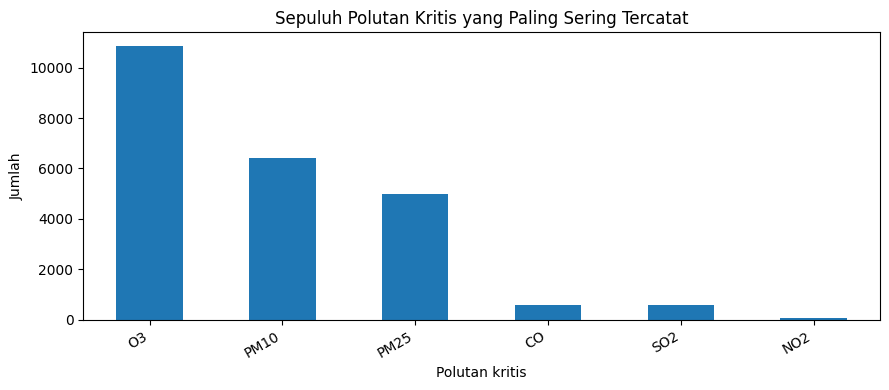

In [24]:
if "critical" in df.columns:
    display(df["critical"].value_counts(dropna=False).head(10).to_frame("jumlah"))
    df["critical"].value_counts().head(10).plot(kind="bar", figsize=(9, 4))
    plt.title("Sepuluh Polutan Kritis yang Paling Sering Tercatat")
    plt.xlabel("Polutan kritis")
    plt.ylabel("Jumlah")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Kolom 'critical' tidak tersedia.")

### 3.7 Ringkasan Kualitas Data
Ringkasan ini mencetak hal-hal yang perlu diperhatikan sebelum pemodelan: celah tahun, nilai hilang, duplikasi, dan jumlah baris per stasiun. Baris duplikat tanggal-stasiun ditangani secara konservatif dengan menyimpan satu baris pertama; periksa konflik nilai bila terdapat duplikat.

In [25]:
print("Jumlah baris:", len(df))
print("Tanggal tidak valid:", df["tanggal"].isna().sum())
print("Duplikat penuh:", df.duplicated().sum())
print("Duplikat tanggal-stasiun:", df.duplicated(["tanggal", "stasiun"]).sum())
print("Jumlah data per tahun:")
display(df.groupby(df["tanggal"].dt.year).size().rename("jumlah_baris").to_frame())

Jumlah baris: 25865
Tanggal tidak valid: 0
Duplikat penuh: 0
Duplikat tanggal-stasiun: 0
Jumlah data per tahun:


,jumlah_baris
tanggal,
2010,1825
2011,1825
2012,1830
2013,1825
2014,1825
2015,1825
2016,1830
2017,1825
2018,1825


## 4. Data Preparation dan Feature Engineering

### 4.1 Pembersihan Dasar
Data diurutkan per stasiun dan tanggal. Duplikat tanggal-stasiun disisakan satu baris. Nilai kategori dirapikan, dan baris tanpa tanggal atau kategori tidak dipakai untuk pemodelan.

In [26]:
df = df.dropna(subset=["tanggal"]).copy()
df = df.sort_values(["stasiun", "tanggal"])
df = df.drop_duplicates(subset=["tanggal", "stasiun"], keep="first")
df["categori"] = df["categori"].astype("string").str.strip()

# Normalisasi variasi penulisan umum jika ditemukan pada data
category_map = {
    "BAIK": "Baik",
    "SEDANG": "Sedang",
    "TIDAK SEHAT": "Tidak Sehat",
    "SANGAT TIDAK SEHAT": "Sangat Tidak Sehat",
    "BERBAHAYA": "Berbahaya"
}
df["categori"] = df["categori"].map(
    lambda x: category_map.get(str(x).strip().upper(), str(x).strip()) if pd.notna(x) else np.nan
)
df = df.dropna(subset=["categori"])
print("Ukuran setelah pembersihan dasar:", df.shape)
display(df.head())

Ukuran setelah pembersihan dasar: (25865, 13)


,tanggal,stasiun,pm25,pm10,so2,co,o3,no2,max,critical,categori,tahun,bulan
0,2010-01-01,DKI1 (Bunderan HI),NaN,60.0,4.0,73.0,27.0,14.0,73.0,CO,Sedang,2010,1
1,2010-01-02,DKI1 (Bunderan HI),NaN,32.0,2.0,16.0,33.0,9.0,33.0,O3,Baik,2010,1
2,2010-01-03,DKI1 (Bunderan HI),NaN,27.0,2.0,19.0,20.0,9.0,27.0,PM10,Baik,2010,1
3,2010-01-04,DKI1 (Bunderan HI),NaN,22.0,2.0,16.0,15.0,6.0,22.0,PM10,Baik,2010,1
4,2010-01-05,DKI1 (Bunderan HI),NaN,25.0,2.0,17.0,15.0,8.0,25.0,PM10,Baik,2010,1


### 4.2 Membentuk Target H+1 dan Fitur Berbasis Masa Lalu
Target adalah kategori pada hari berikutnya di stasiun yang sama. Fitur prediktor menggunakan nilai hari ini (lag 0) untuk memperkirakan besok, sehingga pada saat prediksi semua informasi fitur sudah tersedia. Baris yang jarak tanggalnya bukan tepat satu hari dikeluarkan agar model tidak menganggap dua hari yang terpisah celah data sebagai hari berurutan.

Kolom `categori` hari ini boleh menjadi fitur karena tersedia saat prediksi H+1; kategori target adalah kategori hari berikutnya. Kolom `max` dan `critical` hari berikutnya tidak digunakan sebagai fitur.

In [27]:
df_model = df.sort_values(["stasiun", "tanggal"]).copy()
grouped = df_model.groupby("stasiun", group_keys=False)

df_model["target_h1"] = grouped["categori"].shift(-1)
df_model["tanggal_h1"] = grouped["tanggal"].shift(-1)
df_model["jarak_hari"] = (df_model["tanggal_h1"] - df_model["tanggal"]).dt.days

# Pertahankan hanya pasangan tanggal yang benar-benar berurutan
df_model = df_model[df_model["jarak_hari"].eq(1)].copy()

# Fitur kalender yang diketahui pada tanggal prediksi
df_model["bulan"] = df_model["tanggal"].dt.month
df_model["hari_dalam_minggu"] = df_model["tanggal"].dt.dayofweek
df_model["hari_dalam_tahun"] = df_model["tanggal"].dt.dayofyear

numeric_features = [c for c in ["pm10", "pm25", "so2", "co", "o3", "no2", "max"] if c in df_model.columns]
categorical_features = ["stasiun", "categori"]
if "critical" in df_model.columns:
    categorical_features.append("critical")
numeric_features += ["bulan", "hari_dalam_minggu", "hari_dalam_tahun"]
feature_cols = numeric_features + categorical_features

df_model = df_model.dropna(subset=["target_h1"])
print("Ukuran dataset modeling:", df_model.shape)
print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)
display(df_model[["tanggal", "stasiun", "categori", "target_h1"] + numeric_features[:4]].head())

Ukuran dataset modeling: (25855, 18)
Fitur numerik: ['pm10', 'pm25', 'so2', 'co', 'o3', 'no2', 'max', 'bulan', 'hari_dalam_minggu', 'hari_dalam_tahun']
Fitur kategorikal: ['stasiun', 'categori', 'critical']


,tanggal,stasiun,categori,target_h1,pm10,pm25,so2,co
0,2010-01-01,DKI1 (Bunderan HI),Sedang,Baik,60.0,NaN,4.0,73.0
1,2010-01-02,DKI1 (Bunderan HI),Baik,Baik,32.0,NaN,2.0,16.0
2,2010-01-03,DKI1 (Bunderan HI),Baik,Baik,27.0,NaN,2.0,19.0
3,2010-01-04,DKI1 (Bunderan HI),Baik,Baik,22.0,NaN,2.0,16.0
4,2010-01-05,DKI1 (Bunderan HI),Baik,Baik,25.0,NaN,2.0,17.0


### 4.3 Pembagian Data Latih dan Uji Secara Kronologis
Data latih adalah bagian waktu yang lebih lama, sedangkan data uji adalah 20% bagian paling akhir. Tidak digunakan pembagian acak karena data deret waktu memiliki ketergantungan temporal.

In [28]:
df_model = df_model.sort_values("tanggal").reset_index(drop=True)
split_idx = int(len(df_model) * 0.80)
train_df = df_model.iloc[:split_idx].copy()
test_df = df_model.iloc[split_idx:].copy()

X_train = train_df[feature_cols]
y_train = train_df["target_h1"].astype(str)
X_test = test_df[feature_cols]
y_test = test_df["target_h1"].astype(str)

print("Tanggal latih:", train_df["tanggal"].min(), "s.d.", train_df["tanggal"].max())
print("Tanggal uji  :", test_df["tanggal"].min(), "s.d.", test_df["tanggal"].max())
print("Jumlah data latih:", len(train_df))
print("Jumlah data uji:", len(test_df))
print("\nDistribusi target data latih:")
display(y_train.value_counts(normalize=True).mul(100).round(2).to_frame("persentase"))

Tanggal latih: 2010-01-01 00:00:00 s.d. 2021-04-29 00:00:00
Tanggal uji  : 2021-04-29 00:00:00 s.d. 2025-02-27 00:00:00
Jumlah data latih: 20684
Jumlah data uji: 5171

Distribusi target data latih:


,persentase
target_h1,
Sedang,58.57
Baik,17.50
Tidak Sehat,11.50
TIDAK ADA DATA,11.44
Sangat Tidak Sehat,0.98
Berbahaya,0.00


## 5. Modeling

### 5.1 Preprocessing dan Model
Nilai numerik yang hilang diisi dengan median dan kategori yang hilang diisi dengan nilai paling sering. Variabel kategorikal diubah menggunakan One-Hot Encoding. Semua preprocessing diletakkan dalam `Pipeline` agar parameter imputasi dan encoding dipelajari dari data latih saja.

In [29]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

models = {
    "Dummy (kelas mayoritas)": DummyClassifier(strategy="most_frequent"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

### 5.2 Baseline Persistence
Baseline persistence memprediksi bahwa kategori besok sama dengan kategori hari ini. Baseline dihitung hanya pada data uji yang kategori hari ini tersedia. Ini menjadi pembanding sederhana untuk mengetahui apakah model machine learning memberi nilai tambah.

In [30]:
valid_persistence = test_df["categori"].notna()
if valid_persistence.any():
    y_persist_true = test_df.loc[valid_persistence, "target_h1"].astype(str)
    y_persist_pred = test_df.loc[valid_persistence, "categori"].astype(str)
    print("Baseline persistence")
    print("Accuracy:", round(accuracy_score(y_persist_true, y_persist_pred), 4))
    print("Macro-F1:", round(f1_score(y_persist_true, y_persist_pred, average="macro", zero_division=0), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_persist_true, y_persist_pred), 4))
    print("\nLaporan klasifikasi:")
    print(classification_report(y_persist_true, y_persist_pred, zero_division=0))
else:
    print("Baseline persistence tidak dapat dihitung karena kategori hari ini kosong pada data uji.")

Baseline persistence
Accuracy: 0.7803
Macro-F1: 0.5272
Balanced accuracy: 0.5271

Laporan klasifikasi:
                    precision    recall  f1-score   support

              Baik       0.61      0.61      0.61       593
Sangat Tidak Sehat       0.50      0.50      0.50         4
            Sedang       0.86      0.86      0.86      3922
    TIDAK ADA DATA       0.18      0.18      0.18        39
       Tidak Sehat       0.49      0.49      0.49       613

          accuracy                           0.78      5171
         macro avg       0.53      0.53      0.53      5171
      weighted avg       0.78      0.78      0.78      5171



### 5.3 Melatih dan Mengevaluasi Model
Metrik utama adalah Macro-F1. Recall kategori buruk dihitung dengan menggabungkan kelas `Tidak Sehat`, `Sangat Tidak Sehat`, dan `Berbahaya` sebagai kelas positif. Pastikan ejaan kategori pada dataset sesuai dengan label tersebut.

In [31]:
def safety_metrics(y_true, y_pred):
    bad_labels = {"Tidak Sehat", "Sangat Tidak Sehat", "Berbahaya"}
    y_true_bad = pd.Series(y_true).isin(bad_labels)
    y_pred_bad = pd.Series(y_pred).isin(bad_labels)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_tidak_sehat_plus": recall_score(y_true_bad, y_pred_bad, zero_division=0),
        "precision_tidak_sehat_plus": precision_score(y_true_bad, y_pred_bad, zero_division=0)
    }

results = []
fitted_models = {}
predictions = {}

for name, model in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    predictions[name] = pred
    row = {"model": name, **safety_metrics(y_test, pred)}
    results.append(row)

results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False)
display(results_df.round(4))

,model,accuracy,balanced_accuracy,macro_f1,recall_tidak_sehat_plus,precision_tidak_sehat_plus
1,Random Forest,0.7743,0.3319,0.3252,0.0065,0.2222
0,Dummy (kelas mayoritas),0.7585,0.2000,0.1725,0.0000,0.0000


### 5.4 Laporan Klasifikasi dan Matriks Konfusi

Model dengan Macro-F1 tertinggi: Random Forest
                    precision    recall  f1-score   support

              Baik       0.59      0.54      0.57       593
Sangat Tidak Sehat       0.00      0.00      0.00         4
            Sedang       0.80      0.94      0.86      3922
    TIDAK ADA DATA       0.20      0.18      0.19        39
       Tidak Sehat       0.11      0.00      0.01       613

          accuracy                           0.77      5171
         macro avg       0.34      0.33      0.33      5171
      weighted avg       0.69      0.77      0.72      5171



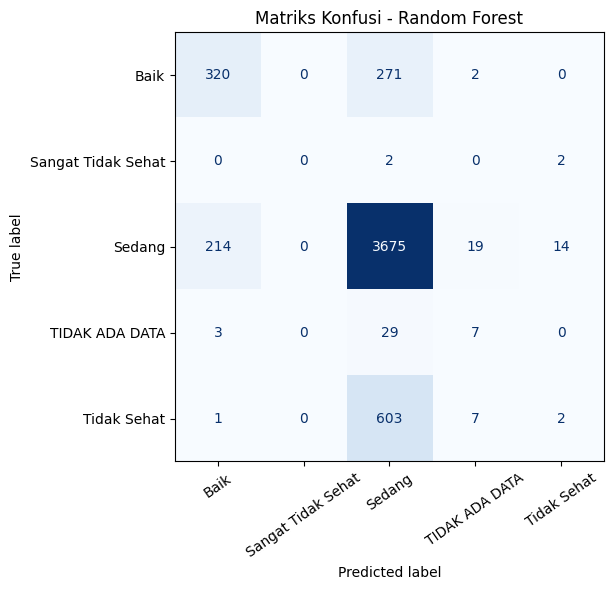

In [32]:
best_name = results_df.iloc[0]["model"]
best_pred = predictions[best_name]
print("Model dengan Macro-F1 tertinggi:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))

labels = sorted(set(y_test) | set(best_pred))
cm = confusion_matrix(y_test, best_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=35, colorbar=False)
plt.title(f"Matriks Konfusi - {best_name}")
plt.tight_layout()
plt.show()

### 5.5 Evaluasi Per Stasiun
Evaluasi per stasiun membantu memeriksa apakah kinerja model berbeda antar lokasi. Hasil dapat kurang stabil pada stasiun/periode dengan data uji sedikit atau kelas tertentu yang tidak muncul.

In [33]:
per_station = []
for station, part in test_df.groupby("stasiun"):
    idx = part.index
    # Samakan indeks prediksi berdasarkan urutan X_test/test_df
    positions = test_df.index.get_indexer(idx)
    pred_station = best_pred[positions]
    true_station = part["target_h1"].astype(str)
    per_station.append({
        "stasiun": station,
        "jumlah_uji": len(part),
        "accuracy": accuracy_score(true_station, pred_station),
        "macro_f1": f1_score(true_station, pred_station, average="macro", zero_division=0),
        "recall_tidak_sehat_plus": safety_metrics(true_station, pred_station)["recall_tidak_sehat_plus"]
    })
display(pd.DataFrame(per_station).round(4))

,stasiun,jumlah_uji,accuracy,macro_f1,recall_tidak_sehat_plus
0,DKI1 (Bunderan HI),1035,0.8116,0.4773,0.0000
1,DKI2 (Kelapa Gading),1034,0.8385,0.3768,0.0000
2,DKI3 (Jagakarsa),1034,0.8520,0.2284,0.0149
3,DKI4 (Lubang Buaya),1034,0.6306,0.3246,0.0097
4,DKI5 (Kebon Jeruk),1034,0.7389,0.4368,0.0000


## 6. Kesimpulan Otomatis untuk Diulas

Bagian ini menampilkan metrik aktual yang dapat digunakan sebagai bahan penulisan hasil. Jangan langsung menyatakan tujuan tercapai sebelum membandingkan Macro-F1 model dengan persistence dan memeriksa recall kategori buruk.

In [34]:
print("=== RINGKASAN EVALUASI ===")
print("Periode uji:", test_df["tanggal"].min(), "sampai", test_df["tanggal"].max())
print("Jumlah data uji:", len(test_df))
print("\nPerbandingan model:")
display(results_df.round(4))

best_row = results_df.iloc[0]
print(f"\nModel terbaik berdasarkan Macro-F1: {best_row['model']}")
print(f"Macro-F1: {best_row['macro_f1']:.4f}")
print(f"Recall kategori Tidak Sehat atau lebih buruk: {best_row['recall_tidak_sehat_plus']:.4f}")
print(f"Precision kategori Tidak Sehat atau lebih buruk: {best_row['precision_tidak_sehat_plus']:.4f}")

print("\nCatatan interpretasi:")
print("- Periksa apakah Macro-F1 mengungguli baseline persistence.")
print("- Recall rendah berarti sebagian hari dengan kualitas udara buruk tidak terdeteksi.")
print("- Hasil hanya berlaku untuk stasiun dan periode yang tercakup oleh data.")
print("- Untuk hasil final laporan, simpan tanggal pemisah latih/uji dan hasil tiap stasiun.")

=== RINGKASAN EVALUASI ===
Periode uji: 2021-04-29 00:00:00 sampai 2025-02-27 00:00:00
Jumlah data uji: 5171

Perbandingan model:


,model,accuracy,balanced_accuracy,macro_f1,recall_tidak_sehat_plus,precision_tidak_sehat_plus
1,Random Forest,0.7743,0.3319,0.3252,0.0065,0.2222
0,Dummy (kelas mayoritas),0.7585,0.2000,0.1725,0.0000,0.0000



Model terbaik berdasarkan Macro-F1: Random Forest
Macro-F1: 0.3252
Recall kategori Tidak Sehat atau lebih buruk: 0.0065
Precision kategori Tidak Sehat atau lebih buruk: 0.2222

Catatan interpretasi:
- Periksa apakah Macro-F1 mengungguli baseline persistence.
- Recall rendah berarti sebagian hari dengan kualitas udara buruk tidak terdeteksi.
- Hasil hanya berlaku untuk stasiun dan periode yang tercakup oleh data.
- Untuk hasil final laporan, simpan tanggal pemisah latih/uji dan hasil tiap stasiun.


## Referensi Dataset
- Pohan, T. (`senadu34`). (2025). *Air Quality Index in Jakarta* [Dataset]. Kaggle. https://www.kaggle.com/datasets/senadu34/air-quality-index-in-jakarta-2010-2021
- Dinas Lingkungan Hidup Provinsi DKI Jakarta. *Indeks Standar Pencemar Udara (ISPU)*. Satu Data Jakarta.

